# Transit Timing Variations from Inclined and Retrograde Companions

*Matthew Payne*

A planet that transits its star does so like clockwork, unless another planet tugs on it. Then the transits come a little early or a little late. These transit timing variations (TTVs) can reveal planets that do not themselves transit, and might be too small to detect any other way (Miralda-Escudé 2002; Agol et al. 2005; Holman & Murray 2005).

Most early work assumed that the unseen companion orbits in the same plane and the same direction as the transiting planet. But some hot Jupiters orbit at large angles to their star's equator, and some even orbit backwards. What if the companion is on an inclined, or a retrograde, orbit? This notebook reproduces, with direct numerical experiments, the main results of

> M. J. Payne, E. B. Ford & D. Veras (2010), *Transit Timing Variations for Inclined and Retrograde Exoplanetary Systems*, ApJL **712**, L86. [ADS](https://ui.adsabs.harvard.edu/abs/2010ApJ...712L..86P/abstract) · [arXiv:1003.2418](https://arxiv.org/abs/1003.2418)

which we refer to as PFV10.

We will:

1. Set up PFV10's fiducial system: a hot Jupiter, perturbed by an Earth-mass companion.
2. Measure transit times from an $N$-body integration, as PFV10 do, and check the method.
3. Compare the TTVs for prograde, polar and retrograde companions, on and off resonance.
4. Map the TTV amplitude against the companion's eccentricity and inclination.
5. Map the "flames of resonance" in semi-major axis and eccentricity, and watch them shrink as the companion's orbit tilts and reverses.
6. Quantify the paper's conclusion: for a retrograde companion, "absence of evidence is not evidence of absence".

Figure numbers in the text refer to PFV10.

**Requirements:** `numpy`, `matplotlib` and `rebound` (version 4 or later).

**Run time:** the maps take about 100,000 integrations, about 50 minutes on a 12-core laptop. Their results are cached in `cache/`, so the notebook normally re-runs in under a minute. Set `RECOMPUTE = True` to redo them, or `QUICK = True` for coarse maps that take a few minutes.

In [1]:
import os
import time
import warnings
from multiprocessing import Pool

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import BoundaryNorm, ListedColormap

import ttv   # helper module in this folder: the system, transit timing and Hill stability

QUICK = False          # True: coarse grids, a few minutes from scratch
RECOMPUTE = False      # True: ignore cached results and integrate again
NPROC = os.cpu_count()
CACHE = "cache_quick" if QUICK else "cache"
print(f"Using {NPROC} processes; QUICK = {QUICK}; RECOMPUTE = {RECOMPUTE}")

# PFV10's colour key for the RMS TTV, in seconds
BINS = [0, 1, 3, 10, 30, 100, 300, 1000, 3000]
BIN_LABELS = ["0-1", "1-3", "3-10", "10-30", "30-100", "100-300", "300-1000", "1000+"]
TTV_CMAP = ListedColormap(plt.cm.viridis(np.linspace(0, 1, len(BIN_LABELS))))
TTV_CMAP.set_bad("0.85")      # grey: no simulation (not Hill stable)
TTV_NORM = BoundaryNorm(BINS, TTV_CMAP.N)

def ttv_image(ax, x, y, values):
    return ax.pcolormesh(x, y, np.ma.masked_invalid(values), cmap=TTV_CMAP, norm=TTV_NORM,
                         shading="nearest", rasterized=True)

def ttv_colorbar(fig, im, ax):
    cb = fig.colorbar(im, ax=ax, ticks=[(BINS[k] + BINS[k + 1]) / 2 if k < len(BIN_LABELS) - 1 else 2000 for k in range(len(BIN_LABELS))])
    cb.ax.set_yticklabels(BIN_LABELS); cb.set_label("RMS TTV (s); grey: not simulated")
    return cb

N_REAL = 3 if QUICK else 5      # PFV10: five orbits with random omega, Omega and M per grid point

Using 12 processes; QUICK = False; RECOMPUTE = False


## 1. The fiducial system

PFV10 consider a transiting hot Jupiter, with mass $M_1 = M_J$, eccentricity $e_1 = 0$ and semi-major axis $a_1 = 0.05$ au, and an Earth-mass companion that perturbs its transit times. The companion's semi-major axis $a_2$, eccentricity $e_2$ and inclination $i_2$ relative to the hot Jupiter's orbit are varied. Each system is integrated for about 10 years, about 1,000 transits of the hot Jupiter.

The paper does not state the star's mass or radius, so we assume a Sun-like star: $1\,M_\odot$ and $1\,R_\odot$.

The companion's inclination $i_2$ runs from $0°$ (coplanar, orbiting in the same direction) through $90°$ (polar) to $180°$ (coplanar but orbiting backwards, *retrograde*).

In [2]:
sim = ttv.make_sim(2.0 ** (2 / 3), 0.0, 0.0)
P1 = sim.particles[1].P
print(f"Hot Jupiter: P1 = {P1:.4f} days, so {ttv.T_END / P1:.0f} orbits in {ttv.T_END / ttv.YEAR_D:.0f} years")
for name, ar in [("2:1", 1.59), ("3:1", 2.08), ("5:1", 2.92), ("near 2:1", 1.63), ("non-resonant", 3.6)]:
    print(f"  a2/a1 = {ar:4.2f} ({name:12s}): P2/P1 = {ar ** 1.5:.3f}")

Hot Jupiter: P1 = 4.0817 days, so 895 orbits in 10 years
  a2/a1 = 1.59 (2:1         ): P2/P1 = 2.005
  a2/a1 = 2.08 (3:1         ): P2/P1 = 3.000
  a2/a1 = 2.92 (5:1         ): P2/P1 = 4.990
  a2/a1 = 1.63 (near 2:1    ): P2/P1 = 2.081
  a2/a1 = 3.60 (non-resonant): P2/P1 = 6.831


The period ratios above are Kepler's third law, $P_2/P_1 = (a_2/a_1)^{3/2}$; PFV10 quote the same values.

## 2. Measuring transit times

PFV10 Section 2.1 describes their method, which we follow with REBOUND's IAS15 integrator (Rein & Liu 2012; Rein & Spiegel 2015) in place of their Bulirsch–Stoer integrator.

* **Transit search:** the hot Jupiter orbits in the $x$–$y$ plane and the observer is far away along $+x$. After each step (a twelfth of an orbit), we test whether the projected star–planet separation $\Delta$ has passed through a minimum while the planet is in front of the star.
* **Refining:** the time of minimum $\Delta$ is found by Newton–Raphson iteration on $\mathrm{d}(\Delta^2)/\mathrm{d}t = 0$. If $\Delta$ is then smaller than the stellar radius, it is a transit.
* **Light travel time:** the star wobbles about the barycentre, so the transits happen at slightly different distances from the observer. PFV10 correct each time by $\delta t_\mathrm{ltt} \simeq -(\mathbf{r}_p \cdot \hat{\mathbf{r}}_\mathrm{los})/c$, with $\mathbf{r}_p$ the planet's barycentric position.
* **TTVs:** the residuals from a straight-line fit, $\delta t(i) = t_i + \delta t_\mathrm{ltt}(i) - i\hat{P} - \hat{t}_0$. The amplitude of a system is the RMS of $\delta t(i)$.

Two checks of the method: with no companion the TTVs must vanish, and the light-travel-time correction should be about $a_1/c$, since the planet is about $a_1$ in front of the barycentre at mid-transit.

In [3]:
tt0 = ttv.transit_times(ttv.make_sim(3.6, 0.0, 0.0, m2=0.0))
r0, (P_fit, t0_fit) = ttv.ttv(tt0)
print(f"No companion: {len(tt0)} transits, period {P_fit:.6f} days, RMS TTV {np.sqrt(np.mean(r0 ** 2)) * ttv.DAY_S:.1e} s")

tt_l = ttv.transit_times(ttv.make_sim(1.59, 0.02, 0.0))
tt_n = ttv.transit_times(ttv.make_sim(1.59, 0.02, 0.0), light_time=False)
d = (tt_l - tt_n) * ttv.DAY_S
print(f"Light-travel-time correction: {d.mean():.2f} s on average (a1 / c = {ttv.A1 / ttv.C_AU_PER_DAY * ttv.DAY_S:.2f} s), "
      f"varying by {d.max() - d.min():.3f} s from transit to transit")
print(f"Effect on the TTVs: RMS {np.sqrt(np.mean((ttv.ttv(tt_l)[0] - ttv.ttv(tt_n)[0]) ** 2)) * ttv.DAY_S:.4f} s")

No companion: 894 transits, period 4.081748 days, RMS TTV 3.4e-07 s


Light-travel-time correction: -24.92 s on average (a1 / c = 24.95 s), varying by 0.034 s from transit to transit
Effect on the TTVs: RMS 0.0065 s


With no companion, the transit times follow a straight line to within rounding error, so the method adds no spurious signal. The light-travel-time correction is about 25 s, essentially constant, so it is absorbed into the fitted $\hat t_0$; its variations change the TTVs by less than a hundredth of a second here. It matters more for planets on wider orbits and for perturbers that move the star more.

## 3. Example TTVs

PFV10 Figure 1 shows the TTVs over 10 years for six companion orbits, at inclinations of $0°$, $45°$, $90°$ and $180°$:

* (a) on the 2:1 resonance, $a_2/a_1 = 1.59$, $e_2 = 0.02$;
* (b) on the 3:1 resonance, $a_2/a_1 = 2.08$, $e_2 = 0.12$;
* (c) on the 5:1 resonance, $a_2/a_1 = 2.92$, $e_2 = 0.05$;
* (d) just outside the 2:1 resonance, $a_2/a_1 = 1.63$, $e_2 = 0.05$;
* (e) non-resonant, $a_2/a_1 = 3.6$, $e_2 = 0.15$;
* (f) non-resonant, $a_2/a_1 = 3.6$, $e_2 = 0.55$.

Panel (a) of the figure is titled $e = 0.025$, but the caption says $e_2 = 0.02$; we use the caption's value.

The paper does not give the companion's other angles (its argument of pericentre $\omega$, longitude of ascending node $\Omega$ and mean anomaly $M$). We set them all to zero. As PFV10 stress (citing Veras & Ford 2009), the TTV amplitude can change by orders of magnitude with these angles. So we should expect the same *kind* of behaviour as in their figure, not identical curves.

24 integrations in 1 s


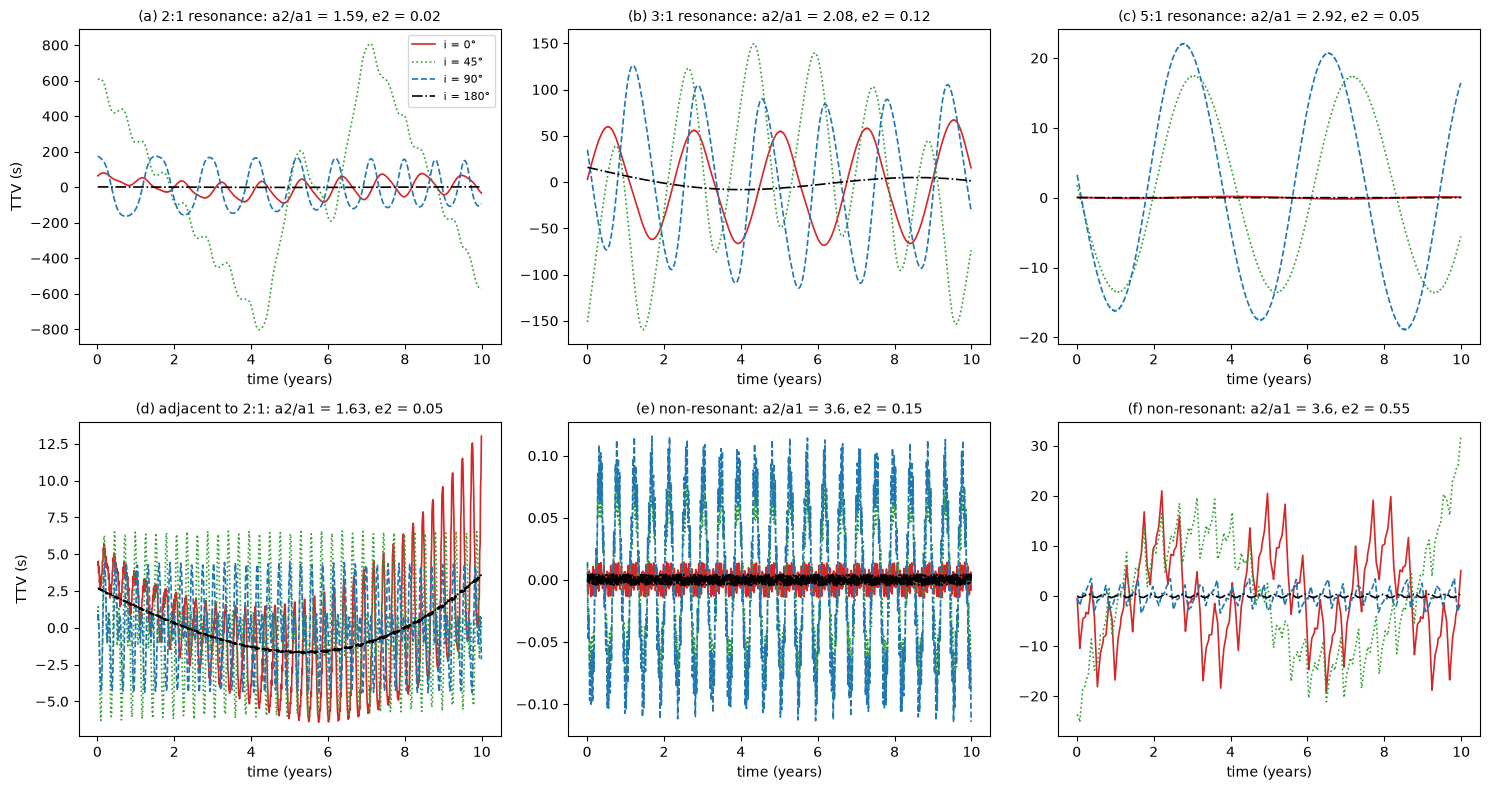

case                        i = 0     i = 45     i = 90    i = 180   (RMS TTV, seconds)
(a) 2:1 resonance            45.2        403        111       1.01
(b) 3:1 resonance            43.1       81.9       69.6       5.93
(c) 5:1 resonance             0.1       10.9       13.4    0.00905
(d) adjacent to 2:1          3.78       3.66       2.53       1.45
(e) non-resonant          0.00854     0.0496     0.0645    0.00309
(f) non-resonant             8.54       11.7       1.57      0.231


In [4]:
CASES = [("(a) 2:1 resonance", 1.59, 0.02), ("(b) 3:1 resonance", 2.08, 0.12), ("(c) 5:1 resonance", 2.92, 0.05),
         ("(d) adjacent to 2:1", 1.63, 0.05), ("(e) non-resonant", 3.6, 0.15), ("(f) non-resonant", 3.6, 0.55)]
INCS = [0, 45, 90, 180]
STYLE = {0: ("C3", "-"), 45: ("C2", ":"), 90: ("C0", "--"), 180: ("k", "-.")}

t0 = time.time()
jobs = [(ar, e, np.radians(i), 0.0, 0.0, 0.0) for _, ar, e in CASES for i in INCS]
with Pool(NPROC) as pool:
    SERIES = pool.map(ttv.ttv_series, jobs)
print(f"{len(jobs)} integrations in {time.time() - t0:.0f} s")

fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for k, ((title, ar, e), ax) in enumerate(zip(CASES, axs.flat)):
    for j, inc in enumerate(INCS):
        tt, r = SERIES[k * len(INCS) + j]
        col, ls = STYLE[inc]
        ax.plot(tt / ttv.YEAR_D, r, color=col, ls=ls, lw=1.2, label=f"i = {inc}°")
    ax.set_title(f"{title}: a2/a1 = {ar}, e2 = {e}", fontsize=10)
    ax.set_xlabel("time (years)")
    if k % 3 == 0:
        ax.set_ylabel("TTV (s)")
axs[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'case':22s}" + "".join(f"{'i = %d' % i:>11s}" for i in INCS) + "   (RMS TTV, seconds)")
for k, (title, ar, e) in enumerate(CASES):
    rms = [np.sqrt(np.mean(SERIES[k * len(INCS) + j][1] ** 2)) for j in range(len(INCS))]
    print(f"{title:22s}" + "".join(f"{v:11.3g}" for v in rms))

**Figure 1** (after PFV10 Figure 1). TTVs of the hot Jupiter over 10 years, for six companion orbits and four inclinations: $0°$ (solid red), $45°$ (dotted green), $90°$ (dashed blue) and $180°$, retrograde (dash-dotted black).

Compare with PFV10's descriptions:

* **On the 2:1 resonance (a):** PFV10 found that the prograde TTVs differ in shape but have similar amplitudes, while the retrograde signal is very low, "∼1 second". Our retrograde RMS is also about 1 s. Our prograde amplitudes differ more than theirs, from 45 s to 400 s, but all are far above the retrograde signal. The 3:1 case (b) is qualitatively similar, as PFV10 note.
* **On the 5:1 resonance (c):** as PFV10 found, both $0°$ and $180°$ give low amplitudes and the maximum is near $90°$.
* **Away from resonance (d–f):** as in PFV10, the retrograde signal is the lowest in every case, but the rest of the dependence on inclination "is far from obvious". At low eccentricity (e), the coplanar signal is particularly low, as in PFV10's Figure 1e. The slow quadratic trend in (d) is the kind of long-term drift PFV10 attribute to small changes in $a_2$ at close approaches.

The table gives the RMS of each curve. Because the companion's angles are our choice (all zero) rather than the paper's, individual values differ from PFV10's. The maps below take the median over random angles, as PFV10 did.

### 3.1 A check: the super-period

Close to, but not in, a first-order resonance $j{:}(j-1)$, the dominant TTV is a sinusoid whose period is set by how far the planets are from exact resonance, the "super-period" (e.g. Lithwick, Xie & Wu 2012):

$$P_\mathrm{super} = \frac{1}{\left| j/P_2 - (j-1)/P_1 \right|}.$$

This gives an independent check of the transit timing. The periods in the formula are the planets' *mean* periods. These differ from the initial osculating periods, because the hot Jupiter perturbs the companion's orbit, and the super-period is very sensitive to them so close to resonance. We measure the mean periods from the integration.

In [5]:
tt, r = SERIES[3 * len(INCS) + 0]          # case (d), i = 0
s = ttv.make_sim(1.63, 0.05, 0.0)
P1o, P2o = s.particles[1].P, s.particles[2].P
P1m, P2m = ttv.mean_periods((1.63, 0.05, 0.0, 0.0, 0.0, 0.0))
P_meas = ttv.dominant_period(tt, r)
print(f"Initial osculating periods: P2/P1 = {P2o / P1o:.4f}; super-period {1 / abs(2 / P2o - 1 / P1o):.1f} days")
print(f"Mean periods over the run:  P2/P1 = {P2m / P1m:.4f}; super-period {1 / abs(2 / P2m - 1 / P1m):.1f} days")
print(f"Strongest period in the TTVs: {P_meas:.1f} days")

Initial osculating periods: P2/P1 = 2.0810; super-period 104.8 days
Mean periods over the run:  P2/P1 = 2.0906; super-period 94.1 days
Strongest period in the TTVs: 94.1 days


With the mean periods, the predicted super-period matches the strongest period in the simulated TTVs to better than 0.1%. The initial osculating periods would have overestimated it by about 10%: the companion's mean period is about 0.5% longer than its initial osculating one, which matters a great deal this close to resonance.

## 4. TTV amplitude against eccentricity and inclination

PFV10 Figure 2 maps the RMS TTV in the plane of the companion's eccentricity $e_2$ and inclination $i_2$, at each of the semi-major axes of Figure 1 (a)–(e). As in PFV10 Section 2.2, each grid point is integrated five times, with the companion's $\omega$, $\Omega$ and $M$ drawn at random, and we plot the median of the five RMS values.

Like PFV10, we simulate only orbits that satisfy the prograde coplanar Hill-stability criterion of Gladman (1993), in its orbital-element form

$$\mu^{-3}\left(\mu_1 + \frac{\mu_2}{\lambda^2}\right)\left(\mu_1\gamma_1 + \mu_2\gamma_2\lambda\right)^2 > 1 + \frac{3^{4/3}\mu_1\mu_2}{\mu^{4/3}},$$

with $\mu_i = m_i/M_\star$, $\mu = \mu_1 + \mu_2$, $\lambda = \sqrt{a_2/a_1}$ and $\gamma_i = \sqrt{1 - e_i^2}$. This guarantees that the coplanar orbits never have close encounters, and inclined orbits are at least as stable (PFV10, citing Veras & Armitage 2004). For our masses, the boundary for circular orbits is at $a_2/a_1 \approx 1.27$.

fig2_0: 1500 integrations (0 s)
fig2_1: 2375 integrations (0 s)
fig2_2: 3125 integrations (0 s)
fig2_3: 1625 integrations (0 s)
fig2_4: 3125 integrations (0 s)


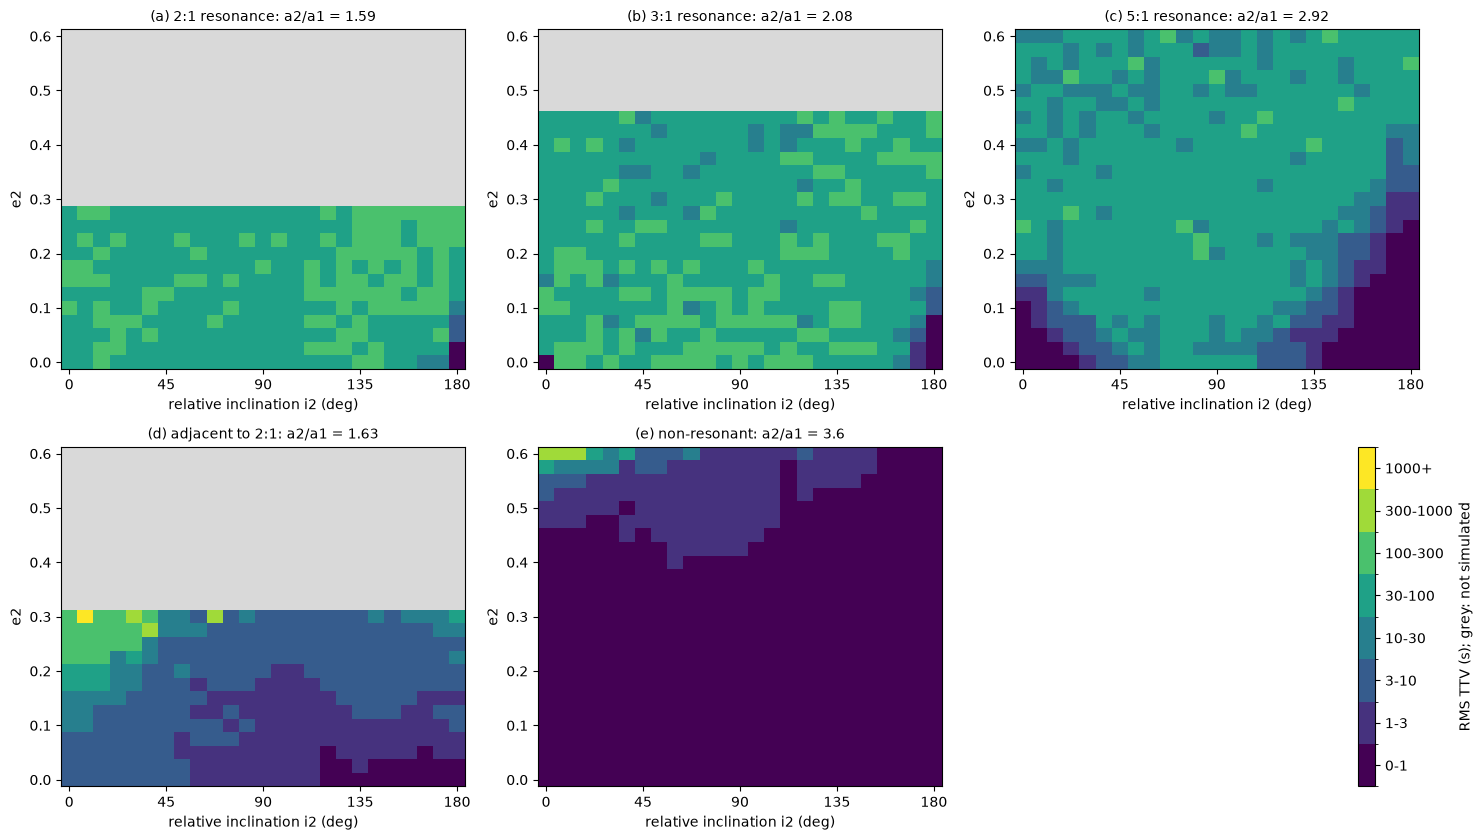

In [6]:
def run_map(name, points, seed):
    # points: list of (a_ratio, e2, inc_deg). Returns the median RMS TTV per point (NaN if not Hill stable).
    points = np.asarray(points, dtype=float)
    stable = ttv.gladman_hill_stable(points[:, 0], points[:, 1])
    ang = ttv.random_angles(len(points) * N_REAL, seed).reshape(len(points), N_REAL, 3)
    jobs = [(a, e, np.radians(i), *ang[k, r]) for k, (a, e, i) in enumerate(points) if stable[k] for r in range(N_REAL)]
    t0 = time.time()
    vals = ttv.cached_grid(f"{CACHE}/{name}.npz", jobs, ttv.rms_ttv, NPROC, recompute=RECOMPUTE)
    out = np.full((len(points), N_REAL), np.nan)
    out[stable] = vals.reshape(-1, N_REAL)
    print(f"{name}: {len(jobs)} integrations ({time.time() - t0:.0f} s)")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)     # grid points that were not simulated are all NaN
        return np.nanmedian(out, axis=1)

E2_GRID = np.linspace(0, 0.6, 13 if QUICK else 25)
I2_GRID = np.linspace(0, 180, 13 if QUICK else 25)
FIG2 = [("(a) 2:1 resonance", 1.59), ("(b) 3:1 resonance", 2.08), ("(c) 5:1 resonance", 2.92),
        ("(d) adjacent to 2:1", 1.63), ("(e) non-resonant", 3.6)]
MAPS2 = {}
for k, (title, ar) in enumerate(FIG2):
    pts = [(ar, e, i) for e in E2_GRID for i in I2_GRID]
    MAPS2[title] = run_map(f"fig2_{k}", pts, seed=100 + k).reshape(len(E2_GRID), len(I2_GRID))

fig, axs = plt.subplots(2, 3, figsize=(15, 8.5))
for (title, ar), ax in zip(FIG2, axs.flat):
    im = ttv_image(ax, I2_GRID, E2_GRID, MAPS2[title])
    ax.set_title(f"{title}: a2/a1 = {ar}", fontsize=10)
    ax.set_xlabel("relative inclination i2 (deg)"); ax.set_ylabel("e2")
    ax.set_xticks([0, 45, 90, 135, 180])
axs[1, 2].axis("off")
ttv_colorbar(fig, im, axs[1, 2])
plt.tight_layout(); plt.show()

**Figure 2** (after PFV10 Figure 2). Median RMS TTV of the hot Jupiter as a function of the companion's eccentricity and inclination, at five fixed semi-major axis ratios, with PFV10's colour key. Grey regions are not Hill stable at $i_2 = 0$, so were not simulated.

PFV10 describe:

* **2:1 (a) and 3:1 (b):** a rather uniform map. The only significant reduction is at low eccentricity near $i_2 = 180°$.
* **5:1 (c):** the low-amplitude region near $180°$ expands, and a second low-amplitude region appears at $e_2 < 0.1$ and $i_2 < 45°$.
* **Adjacent to 2:1 (d):** huge variations with both eccentricity and inclination.
* **Non-resonant (e):** a fairly simple decline in amplitude with inclination.

## 5. The flames of resonance, tilted

PFV10 Figure 3 maps the RMS TTV in the plane of semi-major axis ratio and eccentricity, at several inclinations. For coplanar prograde orbits, this reproduces the result of Agol et al. (2005): small TTVs over most of the plane, with tall "flames of resonance" (Veras & Ford 2009) at the mean-motion resonances, and large TTVs at high eccentricity, where the planets come close.

The text of PFV10 discusses inclinations of $0°$, $30°$, $45°$, $90°$, $135°$ and $180°$; we map those six.

fig3_0: 9470 integrations (0 s)
fig3_1: 9470 integrations (0 s)
fig3_2: 9470 integrations (0 s)
fig3_3: 9470 integrations (0 s)
fig3_4: 9470 integrations (0 s)
fig3_5: 9470 integrations (0 s)


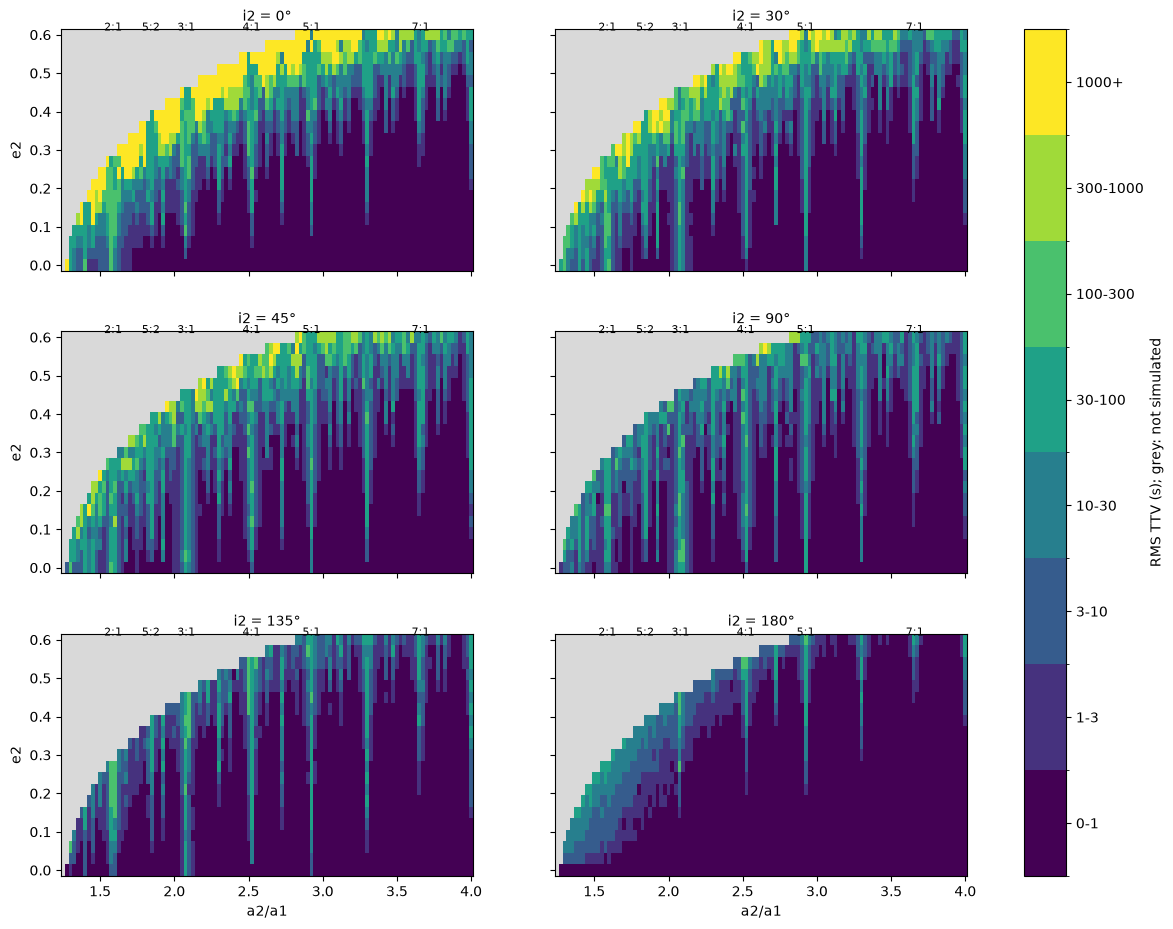

In [7]:
A_GRID = np.linspace(1.25, 4.0, 56 if QUICK else 111)
E3_GRID = np.linspace(0, 0.6, 11 if QUICK else 21)
INC3 = [0, 30, 45, 90, 135, 180]
MAPS3 = {}
for k, inc in enumerate(INC3):
    pts = [(a, e, inc) for e in E3_GRID for a in A_GRID]
    MAPS3[inc] = run_map(f"fig3_{k}", pts, seed=200 + k).reshape(len(E3_GRID), len(A_GRID))

RES = {"2:1": 2 ** (2 / 3), "3:1": 3 ** (2 / 3), "5:2": 2.5 ** (2 / 3), "4:1": 4 ** (2 / 3), "5:1": 5 ** (2 / 3), "7:1": 7 ** (2 / 3)}
fig, axs = plt.subplots(3, 2, figsize=(15, 11), sharex=True, sharey=True)
for inc, ax in zip(INC3, axs.flat):
    im = ttv_image(ax, A_GRID, E3_GRID, MAPS3[inc])
    ax.set_title(f"i2 = {inc}°", fontsize=10)
    for lab, x in RES.items():
        ax.annotate(lab, (x, 0.6), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, annotation_clip=False)
for ax in axs[-1]:
    ax.set_xlabel("a2/a1")
for ax in axs[:, 0]:
    ax.set_ylabel("e2")
fig.subplots_adjust(right=0.88, hspace=0.25)
ttv_colorbar(fig, im, axs.ravel().tolist())
plt.show()

**Figure 3** (after PFV10 Figure 3). Median RMS TTV in the plane of semi-major axis ratio and eccentricity, for six inclinations of the companion's orbit. Labels along the top mark some of the mean-motion resonances.

The coplanar map (top left) shows the flames at the resonances, rising from low eccentricity. Away from resonance, TTVs are below 30 s unless the eccentricity is high. As the inclination grows, PFV10 found:

* **Low inclinations ($30°$, $45°$):** subtle changes. The amplitude falls in some high-eccentricity places, and the spikes of the higher-order resonances reach down to lower eccentricity.
* **$90°$:** the amplitude falls across much of the plane, most of all at high eccentricity.
* **Retrograde ($135°$, $180°$):** large TTVs survive only near the resonances, and the flames themselves are lower and narrower.

Our maps follow the same sequence. At $180°$, a band of moderate TTVs remains just inside the Hill boundary at small separations, matching PFV10's remark that, near low-order resonances, the retrograde amplitude increases slightly at high eccentricity.

## 6. Close to the 2:1 resonance

The 2:1 resonance gives the largest TTVs. PFV10 Figure 4 zooms in on it.

fig4_0: 5020 integrations (0 s)
fig4_1: 5020 integrations (0 s)
fig4_2: 5020 integrations (0 s)
fig4_3: 5020 integrations (0 s)
fig4_4: 5020 integrations (0 s)
fig4_5: 5020 integrations (0 s)


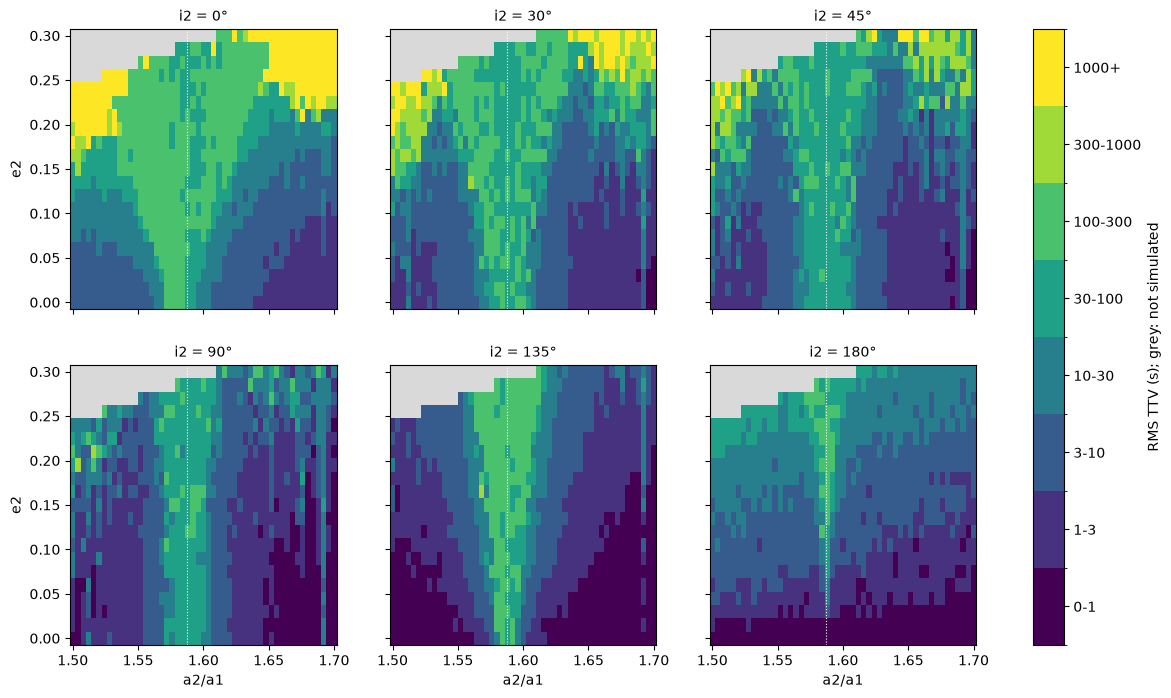

In [8]:
A4_GRID = np.linspace(1.50, 1.70, 26 if QUICK else 51)
E4_GRID = np.linspace(0, 0.3, 11 if QUICK else 21)
MAPS4 = {}
for k, inc in enumerate(INC3):
    pts = [(a, e, inc) for e in E4_GRID for a in A4_GRID]
    MAPS4[inc] = run_map(f"fig4_{k}", pts, seed=300 + k).reshape(len(E4_GRID), len(A4_GRID))

fig, axs = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for inc, ax in zip(INC3, axs.flat):
    im = ttv_image(ax, A4_GRID, E4_GRID, MAPS4[inc])
    ax.axvline(2 ** (2 / 3), color="w", lw=0.8, ls=":")
    ax.set_title(f"i2 = {inc}°", fontsize=10)
for ax in axs[-1]:
    ax.set_xlabel("a2/a1")
for ax in axs[:, 0]:
    ax.set_ylabel("e2")
fig.subplots_adjust(right=0.88, hspace=0.2)
ttv_colorbar(fig, im, axs.ravel().tolist())
plt.show()

**Figure 4** (after PFV10 Figure 4). Close-up of the 2:1 resonance (dotted line, exact commensurability), for six inclinations.

PFV10 found:

* **Coplanar:** near the resonance, a change of a few per cent in $a_2$ or $e_2$ changes the TTV amplitude by more than an order of magnitude.
* **$30°$ and $45°$:** the centre of the resonance keeps roughly the same amplitude, while the regions just outside it fall by about an order of magnitude.
* **$90°$ and $135°$:** TTVs above 30 s survive only in the resonance itself.
* **$180°$:** amplitudes above 100 s are confined to very narrow regions around the first- and second-order resonances.

Our maps show the same progression. One difference: at $180°$, our narrow strip at the resonance reaches 30–100 s, rather than the pockets above 100 s that PFV10 describe. With our random orientations, the median sits just below that threshold.

## 7. Absence of evidence

PFV10's conclusion is that a retrograde companion can hide: almost everywhere in the parameter space, its TTVs would be very small or undetectable. To put a number on this, we use the maps of Section 5. For each inclination, we take the Hill-stable part of the $(a_2/a_1, e_2)$ plane mapped there and find the fraction where the median RMS TTV exceeds a threshold. This summary is ours, not the paper's; the thresholds stand for a detection limit, which depends on the timing precision and the number of transits.

RMS TTV >   3 s: 0°: 44%, 30°: 43%, 45°: 44%, 90°: 36%, 135°: 21%, 180°: 15%
RMS TTV >  10 s: 0°: 35%, 30°: 33%, 45°: 32%, 90°: 23%, 135°: 11%, 180°: 7%
RMS TTV >  30 s: 0°: 26%, 30°: 23%, 45°: 20%, 90°: 12%, 135°: 6%, 180°: 2%
RMS TTV > 100 s: 0°: 16%, 30°: 11%, 45°: 7%, 90°: 2%, 135°: 1%, 180°: 0%


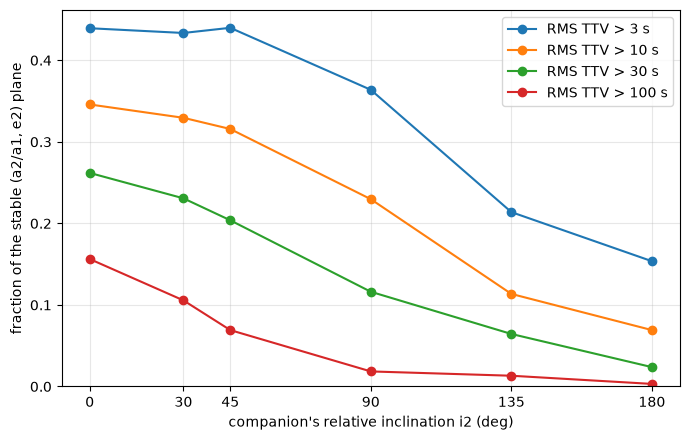

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for thr, col in [(3, "C0"), (10, "C1"), (30, "C2"), (100, "C3")]:
    frac = [np.nanmean(MAPS3[inc][np.isfinite(MAPS3[inc])] > thr) for inc in INC3]
    ax.plot(INC3, frac, "o-", color=col, label=f"RMS TTV > {thr} s")
    print(f"RMS TTV > {thr:3d} s: " + ", ".join(f"{inc}°: {f:.0%}" for inc, f in zip(INC3, frac)))
ax.set_xlabel("companion's relative inclination i2 (deg)"); ax.set_ylabel("fraction of the stable (a2/a1, e2) plane")
ax.set_xticks(INC3); ax.set_ylim(0, None); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

**Figure 5.** The fraction of the Hill-stable $(a_2/a_1, e_2)$ plane of Figure 3 in which an Earth-mass companion produces an RMS TTV above each threshold, against its inclination.

The fraction falls steadily with inclination, and is smallest for retrograde orbits. For example, the part of the plane with an RMS TTV above 30 s shrinks from about a quarter for a coplanar companion to about 2% for a retrograde one. A timing campaign that would detect an Earth-mass companion over a large part of the plane if it were coplanar and prograde would find far less of it if the companion were retrograde. As PFV10 put it, if TTVs are used to rule out companions, "absence of evidence is not evidence of absence".

## Summary

* We followed PFV10's method: $N$-body integrations of a hot Jupiter and an Earth-mass companion, transit times found from the minimum projected separation, a light-travel-time correction, and the RMS of the residuals from a linear ephemeris. With no companion the TTVs vanish, and near the 2:1 resonance their period matches the predicted super-period.
* On low-order resonances, prograde companions at any inclination give TTVs of similar amplitude, while a retrograde companion on the same orbit gives a far smaller signal.
* Over the $(a_2/a_1, e_2)$ plane, the "flames of resonance" of coplanar systems shrink as the companion's orbit tilts, and away from resonance the TTVs fall. Retrograde companions give large TTVs only very close to resonances.
* So the absence of a TTV signal does not rule out a companion if its orbit may be strongly inclined or retrograde.
* Our maps use our own random orientations and a Sun-like star, so individual values differ from PFV10's, but the patterns are the same.

## Going further

* **Interior companions.** PFV10 also consider an Earth-mass planet *inside* the hot Jupiter's orbit (their Figure 5 and Section 3.3.2). Away from resonance the TTVs barely depend on inclination; near resonance they grow towards $90°$ and then fall. Try it by swapping the semi-major axes.
* **Other masses and stars.** The perturber's mass and the star's mass and radius all change the signal. Try a Neptune-mass companion.
* **Transit durations.** Inclined companions also make the hot Jupiter's orbit precess, changing the transit duration. PFV10 suggest combining TTVs with transit duration variations.
* **The wider survey.** Veras, Ford & Payne (2011) quantify, with about $10^7$ simulations, how TTV amplitudes depend on each orbital parameter, and how many transits are needed to characterise an unseen planet. Payne & Ford (2011) apply TTV and radial-velocity analysis to the HAT-P-13 system.

## References

* Agol, E., Steffen, J., Sari, R. & Clarkson, W. 2005, *On detecting terrestrial planets with timing of giant planet transits*, MNRAS 359, 567. [ADS](https://ui.adsabs.harvard.edu/abs/2005MNRAS.359..567A/abstract)
* Gladman, B. 1993, *Dynamics of Systems of Two Close Planets*, Icarus 106, 247. [ADS](https://ui.adsabs.harvard.edu/abs/1993Icar..106..247G/abstract)
* Holman, M. J. & Murray, N. W. 2005, *The Use of Transit Timing to Detect Terrestrial-Mass Extrasolar Planets*, Science 307, 1288. [ADS](https://ui.adsabs.harvard.edu/abs/2005Sci...307.1288H/abstract)
* Lithwick, Y., Xie, J. & Wu, Y. 2012, *Extracting Planet Mass and Eccentricity from TTV Data*, ApJ 761, 122. [ADS](https://ui.adsabs.harvard.edu/abs/2012ApJ...761..122L/abstract)
* Miralda-Escudé, J. 2002, *Orbital Perturbations of Transiting Planets: A Possible Method to Measure Stellar Quadrupoles and to Detect Earth-Mass Planets*, ApJ 564, 1019. [ADS](https://ui.adsabs.harvard.edu/abs/2002ApJ...564.1019M/abstract)
* Payne, M. J. & Ford, E. B. 2011, *An Analysis of Jitter and Transit Timing Variations in the HAT-P-13 System*, ApJ 729, 98. [ADS](https://ui.adsabs.harvard.edu/abs/2011ApJ...729...98P/abstract)
* Payne, M. J., Ford, E. B. & Veras, D. 2010, *Transit Timing Variations for Inclined and Retrograde Exoplanetary Systems*, ApJL 712, L86. [ADS](https://ui.adsabs.harvard.edu/abs/2010ApJ...712L..86P/abstract)
* Rein, H. & Liu, S.-F. 2012, *REBOUND: an open-source multi-purpose N-body code for collisional dynamics*, A&A 537, A128. [ADS](https://ui.adsabs.harvard.edu/abs/2012A&A...537A.128R/abstract)
* Rein, H. & Spiegel, D. S. 2015, *IAS15: a fast, adaptive, high-order integrator for gravitational dynamics*, MNRAS 446, 1424. [ADS](https://ui.adsabs.harvard.edu/abs/2015MNRAS.446.1424R/abstract)
* Veras, D. & Ford, E. B. 2009, *Identifying Non-transiting Terrestrial Planets with Transit Timing Data*, IAU Symp. 253, 486. [ADS](https://ui.adsabs.harvard.edu/abs/2009IAUS..253..486V/abstract)
* Veras, D. & Armitage, P. J. 2004, *The dynamics of two massive planets on inclined orbits*, MNRAS 347, 613. [ADS](https://ui.adsabs.harvard.edu/abs/2004MNRAS.347..613V/abstract)
* Veras, D., Ford, E. B. & Payne, M. J. 2011, *Quantifying the Challenges of Detecting Unseen Planetary Companions with Transit Timing Variations*, ApJ 727, 74. [ADS](https://ui.adsabs.harvard.edu/abs/2011ApJ...727...74V/abstract)